In [1]:
import os
import glob
import numpy as np
import openpyxl
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import gaussian_kde

In [2]:
def count_infant_action(coding_sheet, infant_action_codes, infant_action):
    count=0
    infant_row_num=[x[1] for x in infant_action_codes].index(infant_action)+4
    for col_num in range(3, coding_sheet.max_column + 1):
        cell_value = coding_sheet.cell(row=infant_row_num, column=col_num).value
        if cell_value is not None and len(str(cell_value)):
            count += 1
    return count

def count_mother_action(coding_sheet, mother_action_codes, infant_action_codes, mother_action, split_index, infant_sees=None):
    count=0
    infant_row_num=[x[1] for x in infant_action_codes].index('Focus to Moth')+4
    mother_row_num=[x[1] for x in mother_action_codes].index(mother_action)+split_index+4+1
    for col_num in range(3, coding_sheet.max_column + 1):
        infant_cell_value = coding_sheet.cell(row=infant_row_num, column=col_num).value
        mother_cell_value = coding_sheet.cell(row=mother_row_num, column=col_num).value
        if mother_cell_value is not None and len(str(mother_cell_value)):
            if infant_sees is None or infant_sees==(infant_cell_value is not None and len(str(infant_cell_value))):
                count += 1
    return count
    
def count_mother_mirroring(coding_sheet, mother_action_codes, infant_action_codes, split_index, mirror_type=None, infant_actions=None,
                          infant_sees=None):
    count=0
    infant_row_num=[x[1] for x in infant_action_codes].index('Focus to Moth')+4
    mother_row_nums=[]
    if mirror_type is None:
        for type in ['Direct Mirror', 'Enrich Mirror', 'Partial Mirror', 'Modified Mir']:
            mother_row_nums.append([x[1] for x in mother_action_codes].index(type)+split_index+4+1)
    else:
        mother_row_nums.append([x[1] for x in mother_action_codes].index(mirror_type)+split_index+4+1)

    for mother_row_num in mother_row_nums:
        for col_num in range(3, coding_sheet.max_column + 1):
            infant_cell_value = coding_sheet.cell(row=infant_row_num, column=col_num).value
            mother_cell_value = coding_sheet.cell(row=mother_row_num, column=col_num).value
            if mother_cell_value is not None and '-' in mother_cell_value:
                if infant_sees is None or infant_sees==(infant_cell_value is not None and len(str(infant_cell_value))):
                    mirrored_action_code=mother_cell_value.split('-')[0]
                    mirrored_action=infant_action_codes[[x[0] for x in infant_action_codes].index(mirrored_action_code)][1]
                    if infant_actions is None or mirrored_action in infant_actions:
                        count += 1                
    return count

def count_mother_response(coding_sheet, mother_actions, mother_action_codes, infant_action_codes, split_index, infant_actions=None,
                          infant_sees=None):
    count=0
    infant_row_num=[x[1] for x in infant_action_codes].index('Focus to Moth')+4
    mother_row_nums=[]
    for action in mother_actions:
        mother_row_nums.append([x[1] for x in mother_action_codes].index(action)+split_index+4+1)
    
    for mother_row_num in mother_row_nums:
        for col_num in range(3, coding_sheet.max_column + 1):
            infant_cell_value = coding_sheet.cell(row=infant_row_num, column=col_num).value
            mother_cell_value = coding_sheet.cell(row=mother_row_num, column=col_num).value
            if mother_cell_value is not None and '-' in mother_cell_value:
                if infant_sees is None or infant_sees==(infant_cell_value is not None and len(str(infant_cell_value))):
                    responded_action_code=mother_cell_value.split('-')[0]
                    responded_action=infant_action_codes[[x[0] for x in infant_action_codes].index(responded_action_code)][1]
                    if infant_actions is None or responded_action in infant_actions:
                        count += 1                
    return count
    
def count_mutual_gaze(coding_sheet, infant_action_codes, mother_action_codes, split_index):
    count=0
    infant_row_num=[x[1] for x in infant_action_codes].index('Focus to Moth')+4
    mother_row_num=[x[1] for x in mother_action_codes].index('Gaze to Infant')+split_index+4+1
    for col_num in range(3, coding_sheet.max_column + 1):
        # Get the cell value in the infant's row
        infant_cell_value = coding_sheet.cell(row=infant_row_num, column=col_num).value
        mother_cell_value = coding_sheet.cell(row=mother_row_num, column=col_num).value
        if infant_cell_value is not None and len(str(infant_cell_value)) and mother_cell_value is not None and len(str(mother_cell_value)):
            count += 1
    return count
    

In [3]:
out_base_path='/home/bonaiuto/infant_face_eeg/derivatives/9m'
base_data_path='/home/common/bonaiuto/infant_9m_face_eeg/derivatives'
subject_paths = [x for x in sorted(glob.glob(os.path.join(base_data_path, '*'))) if os.path.isdir(x)]

In [4]:
infant_base_actions={
    'infant_non_comm_mouth': 'Non ComMo',
    'infant_lip_tongue': 'Lip/ton prot',
    'infant_mouth_open': 'Mouth open',
    'infant_yawn': 'Yawn',
    'infant_in_mouth_movement': 'In mouth mov',
    'infant_smile': 'Smile',
    'infant_raise_frown': 'Rais frown',
    'infant_neg_mouth': 'Neg Mouth',
    'infant_neg_eye': 'Neg Eye',
    'infant_cry_face': 'Cry face',
    'infant_cooing_pos_vocal': 'Cooing/Pos Vo',
    'infant_neg_vocal': 'Neg Vocal',
    'infant_bio_noises': 'Bio Noises',
    'infant_gaze_mother': 'Focus to Moth'
}
infant_compound_actions={
    'infant_face_all': ['infant_lip_tongue', 'infant_mouth_open', 'infant_in_mouth_movement', 'infant_smile', 'infant_raise_frown', 'infant_neg_mouth', 'infant_neg_eye', 'infant_cry_face', 'infant_non_comm_mouth'],
}
infant_actions=list(infant_base_actions.keys())
infant_actions.extend(list(infant_compound_actions.keys()))

mother_base_actions={
    'mother_direct_mirror': 'Direct Mirror',
    'mother_enrich_mirror': 'Enrich Mirror',
    'mother_partial_mirror': 'Partial Mirror',
    'mother_modified_mirror': 'Modified Mir',
    'mother_vitality_affect': 'Vitality/Affect ',
    'mother_affirm_mark': 'Affirm mark',
    'mother_cont_maint': 'Cont Maint',
    'mother_hyper_mirror': 'Hyper mirror',
    'mother_hyper_mark': 'Hyper mark',        
    'mother_hypo_mirror': 'Hypo mirror',
    'mother_hypo_mark': 'Hypo mark',
    'mother_negating': 'Negating',
}
mother_compound_actions={
    'mother_mirror': ['mother_direct_mirror', 'mother_enrich_mirror','mother_partial_mirror','mother_modified_mirror'],
    'mother_all': ['mother_direct_mirror', 'mother_enrich_mirror','mother_partial_mirror','mother_modified_mirror', 'mother_affirm_mark','mother_cont_maint', 'mother_hyper_mirror', 'mother_hyper_mark', 'mother_hypo_mirror', 'mother_hypo_mark', 'mother_negating'],    
}
mother_actions=list(mother_base_actions.keys())
mother_actions.extend(mother_compound_actions.keys())


def process_data(infant_sees=None):
    data = {
        'subject': [],                
    }
    for action in infant_actions:
        data[action]=np.zeros(len(subject_paths))*np.nan
    for action in mother_actions:
        data[action]=np.zeros(len(subject_paths))*np.nan
    for key in mother_actions:                
        for infant_key in infant_actions:
            col_name=f'{key}_{infant_key}'
            data[col_name]=np.zeros(len(subject_paths))*np.nan
            
    for s_idx, subject_path in enumerate(subject_paths):
        subject=os.path.split(subject_path)[-1]
        data['subject'].append(subject)
        if not (subject=='119' or subject=='131'):
            print(f'Processing subject {subject}')
            
            fname=os.path.join(subject_path, f'{subject} NEW.xlsm')
            workbook=openpyxl.load_workbook(fname, data_only=True)
        
            coding_sheet = workbook['Coding']
            timestamps = [cell.value for cell in coding_sheet[2] if cell.column >= 3]
            action_codes_and_labels = [(coding_sheet.cell(row=row, column=1).value,
                                       coding_sheet.cell(row=row, column=2).value)
                                      for row in range(4, coding_sheet.max_row + 1)]
            blank_row_index = [index for index, (code, label) in enumerate(action_codes_and_labels) if code is None]
            split_index = blank_row_index[0]
            infant_action_codes = action_codes_and_labels[:split_index]
            mother_action_codes = action_codes_and_labels[split_index+1:]

            for key in infant_base_actions.keys():
                data[key][s_idx]=count_infant_action(coding_sheet, infant_action_codes, infant_base_actions[key])

            for key in infant_compound_actions.keys():
                data[key][s_idx]=0
                for base_action in infant_compound_actions[key]:
                    data[key][s_idx]+=data[base_action][s_idx]
                    
            for key in mother_base_actions.keys():                
                data[key][s_idx]=count_mother_response(
                    coding_sheet, 
                    [mother_base_actions[key]], 
                    mother_action_codes, 
                    infant_action_codes, 
                    split_index, 
                    infant_actions=None,
                    infant_sees=infant_sees
                )
                for infant_key in infant_base_actions.keys():
                    col_name=f'{key}_{infant_key}'
                    data[col_name][s_idx]=count_mother_response(
                        coding_sheet,
                        [mother_base_actions[key]],
                        mother_action_codes,
                        infant_action_codes,
                        split_index,
                        infant_actions=[infant_base_actions[infant_key]],
                        infant_sees=infant_sees
                    )
                for infant_key in infant_compound_actions.keys():
                    col_name=f'{key}_{infant_key}'
                    base_action_codes=[infant_base_actions[x] for x in infant_compound_actions[infant_key]]
                    data[col_name][s_idx]=count_mother_response(
                        coding_sheet,
                        [mother_base_actions[key]],
                        mother_action_codes,
                        infant_action_codes,
                        split_index,
                        infant_actions=base_action_codes,
                        infant_sees=infant_sees
                    )
                    
            for key in mother_compound_actions.keys():
                data[key][s_idx]=0
                for base_action in mother_compound_actions[key]:
                    data[key][s_idx]+=data[base_action][s_idx]
                for infant_key in infant_actions:
                    col_name=f'{key}_{infant_key}'
                    data[col_name][s_idx]=0
                    for base_action in mother_compound_actions[key]:
                        data[col_name][s_idx]+=data[f'{base_action}_{infant_key}'][s_idx]
            #data['mother_mirror_face_voc'][s_idx]=data['mother_direct_mirror_face_voc'][s_idx]+data['mother_enrich_mirror_face_voc'][s_idx]+data['mother_partial_mirror_face_voc'][s_idx]+data['mother_modified_mirror_face_voc'][s_idx]            

    

    return data

In [5]:
data=process_data()

Processing subject 102
Processing subject 103
Processing subject 108
Processing subject 109
Processing subject 111
Processing subject 112
Processing subject 113
Processing subject 114
Processing subject 117
Processing subject 121
Processing subject 122
Processing subject 123
Processing subject 126
Processing subject 127
Processing subject 128
Processing subject 129
Processing subject 130
Processing subject 133
Processing subject 138
Processing subject 139
Processing subject 141
Processing subject 148
Processing subject 149


In [6]:
infant_keys=[
    'infant_face_all'
]
mother_keys=[
    'mother_mirror',
    'mother_direct_mirror', 
    'mother_enrich_mirror',
    'mother_modified_mirror',
    'mother_affirm_mark',
    'mother_all'
]
keys=[]
keys.extend(infant_keys)
keys.extend(mother_keys)

for infant_key in infant_keys:
    for mother_key in mother_keys:
        col_name=f'prop_{infant_key}-{mother_key}'
        data[col_name]=data[f'{mother_key}_{infant_key}']/data[infant_key]
        keys.append(col_name)

data['prop_infant_face_all-mother_mirror_infant_face_all']=data['mother_mirror_infant_face_all']/data['infant_face_all']

data['prop_infant_face_all-mother_affirm_mark_infant_face_all']=data['mother_affirm_mark_infant_face_all']/data['infant_face_all']
data['prop_infant_face_all-mother_direct_mirror_infant_face_all']=data['mother_direct_mirror_infant_face_all']/data['infant_face_all']
data['prop_infant_face_all-mother_enrich_mirror_infant_face_all']=data['mother_enrich_mirror_infant_face_all']/data['infant_face_all']
data['prop_infant_face_all-mother_modified_mirror_infant_face_all']=data['mother_modified_mirror_infant_face_all']/data['infant_face_all']


In [7]:
# Convert dictionary to DataFrame
data_df = pd.DataFrame(data)

# Write DataFrame to CSV
csv_file_path = os.path.join(out_base_path, 'behavior_2m.csv')
data_df.to_csv(csv_file_path, index=False)

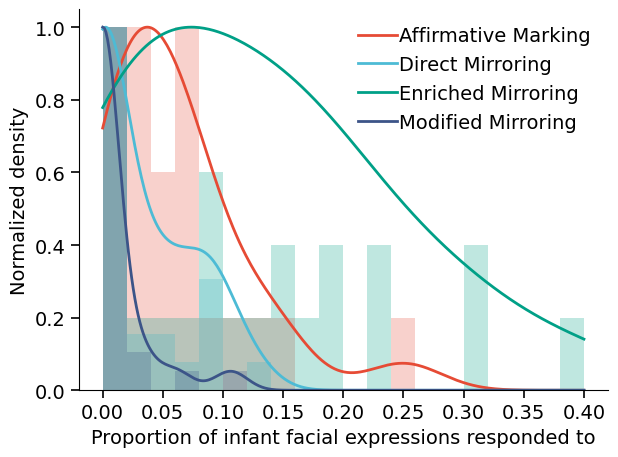

In [8]:
vars_to_plot = [
    'prop_infant_face_all-mother_affirm_mark_infant_face_all',
    'prop_infant_face_all-mother_direct_mirror_infant_face_all',
    'prop_infant_face_all-mother_enrich_mirror_infant_face_all',
    'prop_infant_face_all-mother_modified_mirror_infant_face_all'
]

labels = [
    'Affirmative Marking',
    'Direct Mirroring',
    'Enriched Mirroring',
    'Modified Mirroring'
]

behavior_colors = {
    'prop_infant_face_all-mother_affirm_mark_infant_face_all': '#E64B35',
    'prop_infant_face_all-mother_direct_mirror_infant_face_all': '#4DBBD5',
    'prop_infant_face_all-mother_enrich_mirror_infant_face_all': '#00A087',
    'prop_infant_face_all-mother_modified_mirror_infant_face_all': '#3C5488'
}

all_values = []
for var in vars_to_plot:
    v = np.asarray(data[var], dtype=float)
    v = v[np.isfinite(v)]
    all_values.append(v)

all_values = np.concatenate(all_values)

global_min = float(np.min(all_values))
global_max = float(np.max(all_values))

bins = 20
bin_edges = np.linspace(global_min, global_max, bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
bin_width = bin_edges[1] - bin_edges[0]

x_grid = np.linspace(global_min, global_max, 300)

plt.rcParams.update({
    'font.size': 14,
    'axes.spines.right': False,
    'axes.spines.top': False,
    'xtick.major.size': 6,
    'xtick.major.width': 1.2,
    'ytick.major.size': 6,
    'ytick.major.width': 1.2,
    'legend.frameon': False,
    'legend.handletextpad': 0.1,
    'svg.fonttype': 'none',
    'text.usetex': False
})

plt.figure()

for var, label in zip(vars_to_plot, labels):
    color = behavior_colors[var]

    values = np.asarray(data[var], dtype=float)
    values = values[np.isfinite(values)]
    if values.size < 2:
        continue

    # Histogram (shared bins; peak-normalized)
    hist_counts, _ = np.histogram(values, bins=bin_edges)
    if np.max(hist_counts) > 0:
        hist_heights = hist_counts / np.max(hist_counts)
        plt.bar(
            bin_centers,
            hist_heights,
            width=bin_width,
            alpha=0.25,
            color=color,
            edgecolor='none'
        )

    if float(np.min(values)) != float(np.max(values)):
        kde = gaussian_kde(values)
        y = kde(x_grid)
        y = y / np.max(y)  # peak normalize
        plt.plot(x_grid, y, color=color, linewidth=2, label=label)
    else:
        plt.plot([values[0]], [1.0], marker='o', color=color, label=label)

plt.xlabel("Proportion of infant facial expressions responded to")
plt.ylabel("Normalized density")
plt.ylim(0, 1.05)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('../output/behavior_2m.png')
plt.savefig('../output/behavior_2m.pdf')